In [61]:
import numpy as np
import pandas as pd
import time
import shap
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE
from sklearn.metrics import classification_report

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import cross_val_score

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)


Caching the list of root modules, please wait!
(This will only be done once - type '%rehashx' to reset cache!)



c:\Users\sokhn\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
data = pd.read_csv("dataset_SO.csv")
data.head()



,id,serie,nom_spe1,nom_spe2,note_maths,note_francais,note_anglais,note_philo,note_hg,note_spe1,...,score_S,score_E,score_C,code_holland,stress,social,autonomie,adaptabilite,branche,categorie
0,1,L1,LV2,—,11.71,14.19,14.99,16.39,14.44,13.33,...,4.66,4.79,3.78,ESC,3.49,4.65,3.68,3.97,Sciences Politiques,Droit & Sciences Politiques
1,2,S1,Physique-Chimie,—,13.56,14.46,15.57,12.72,13.78,17.23,...,4.24,3.11,3.66,ISR,4.54,4.49,3.73,3.97,Médecine,Sciences de la Santé
2,3,L1,LV2,—,11.01,17.88,18.04,16.04,13.55,15.41,...,4.50,4.46,3.70,SEC,3.85,3.98,3.67,4.25,Sciences Politiques,Droit & Sciences Politiques
3,4,L2,LV2,—,8.61,17.35,14.43,13.62,17.03,16.96,...,4.43,4.69,3.35,ESI,3.47,4.55,3.76,3.92,Sciences Politiques,Droit & Sciences Politiques
4,5,L2,LV2,—,8.05,13.03,12.87,14.79,15.17,12.72,...,4.82,2.99,2.44,SIA,3.35,4.47,3.38,5.00,Sociologie,Sciences Humaines & Sociales


In [3]:
data.shape

(6830, 27)

In [4]:
data.dtypes

id                 int64
serie                str
nom_spe1             str
nom_spe2             str
note_maths       float64
note_francais    float64
note_anglais     float64
note_philo       float64
note_hg          float64
note_spe1        float64
note_spe2        float64
moy_sciences     float64
moy_lettres      float64
moy_globale      float64
score_R          float64
score_I          float64
score_A          float64
score_S          float64
score_E          float64
score_C          float64
code_holland         str
stress           float64
social           float64
autonomie        float64
adaptabilite     float64
branche              str
categorie            str
dtype: object

In [5]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 6830 entries, 0 to 6829
Data columns (total 27 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   id             6830 non-null   int64  
 1   serie          6830 non-null   str    
 2   nom_spe1       6830 non-null   str    
 3   nom_spe2       6830 non-null   str    
 4   note_maths     6830 non-null   float64
 5   note_francais  6830 non-null   float64
 6   note_anglais   6830 non-null   float64
 7   note_philo     6830 non-null   float64
 8   note_hg        6830 non-null   float64
 9   note_spe1      6830 non-null   float64
 10  note_spe2      6830 non-null   float64
 11  moy_sciences   6830 non-null   float64
 12  moy_lettres    6830 non-null   float64
 13  moy_globale    6830 non-null   float64
 14  score_R        6830 non-null   float64
 15  score_I        6830 non-null   float64
 16  score_A        6830 non-null   float64
 17  score_S        6830 non-null   float64
 18  score_E        6830

In [6]:
print (data.isnull().sum())

id               0
serie            0
nom_spe1         0
nom_spe2         0
note_maths       0
note_francais    0
note_anglais     0
note_philo       0
note_hg          0
note_spe1        0
note_spe2        0
moy_sciences     0
moy_lettres      0
moy_globale      0
score_R          0
score_I          0
score_A          0
score_S          0
score_E          0
score_C          0
code_holland     0
stress           0
social           0
autonomie        0
adaptabilite     0
branche          0
categorie        0
dtype: int64


Suppression des colonnes inutiles

In [7]:
data = data.drop(columns=['id'])

Nous allons faire une prédiction a 2 niveaux, pour le premier niveau, nous allons faire des predictions juste avec la variable catégorie sans oublier d'enlever la variable branche dans X, et ensuite avec la variable branche

Séparation des variables cibles 

In [8]:
X_cat = data.drop(columns=['categorie', 'branche'])
y_cat= data['categorie']

Nous allons procéder à l'encodage de y avec LabelEncoder car XGBoost ne prend pas en compte le texte, ensuite nous ferons un inverse statement lors des prédictions.

In [9]:
label_encoder_cat = LabelEncoder()

y_cat = label_encoder_cat.fit_transform(y_cat)

In [10]:
#vérification des correspondances

for i, classe in enumerate(label_encoder_cat.classes_):
    print(i, "->", classe)

0 -> Agriculture & Environnement
1 -> Arts & Culture
2 -> Droit & Sciences Politiques
3 -> Lettres & Communication
4 -> Multimédia & Création Numérique
5 -> Sciences & Technologies
6 -> Sciences Humaines & Sociales
7 -> Sciences de la Santé
8 -> Sciences Économiques & Gestion


Les modèles ne comprenant pas le texte, il va falloir encoder les variables catégorielles, exemple : serie, nom_spe1 etc...
tout d'abord il faut identifier ces variables, ensuite nous allons gérer l'encodage avec OneHotEncoder.

In [11]:
cat_cols= X_cat.select_dtypes(include=['object', 'str']).columns
num_cols= X_cat.select_dtypes(include=['int64', 'float64']).columns

In [12]:
preprocessor_cat = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)
    ]
)

Nous allons effetuer un split de 70/15/15, train/val/test.
Nous allons fire 2 splits, dans un premier temps séparer le train du reste, ensuite séparer val et test.

In [13]:
X_train_cat, X_temp_cat, y_train_cat, y_temp_cat = train_test_split (
    X_cat,
    y_cat,
    test_size=0.30, 
    random_state=42,
    stratify=y_cat

)

In [14]:
X_val_cat, X_test_cat, y_val_cat, y_test_cat= train_test_split (
    X_temp_cat,
    y_temp_cat,
    test_size=0.50,
    random_state=42,
    stratify=y_temp_cat
)

Application du prétraitement

In [15]:
#fit sur train
X_train_cat_processed= preprocessor_cat.fit_transform(X_train_cat)

#transform seulement sur val et test
X_val_cat_processed = preprocessor_cat.transform(X_val_cat)
X_test_cat_processed = preprocessor_cat.transform(X_test_cat)


Nous allons utilisé SMOTE pour corriger le déséquilibre des classes dans le dataset. Cette méthode génère artificiellement de nouveaux exemples pour les classes minoritaires afin d’éviter que le modèle soit biaisé vers les classes majoritaires.

In [16]:
print(pd.Series (y_train_cat).value_counts())

5    1106
7     840
8     518
4     490
0     455
6     385
2     364
3     343
1     280
Name: count, dtype: int64


In [17]:
classes, counts = np.unique (y_train_cat, return_counts=True)
strat_smote = {}
for cl, co in zip(classes, counts):
    if co < 700 :
        strat_smote[cl]= 700
    else:
        strat_smote[cl]= co
print ("Stratégie planifiée :", strat_smote)

smote_cat= SMOTE(sampling_strategy=strat_smote, random_state=42)
X_train_cat_smote, y_train_cat_smote = smote_cat.fit_resample (
    X_train_cat_processed,
    y_train_cat
)

Stratégie planifiée : {np.int64(0): 700, np.int64(1): 700, np.int64(2): 700, np.int64(3): 700, np.int64(4): 700, np.int64(5): np.int64(1106), np.int64(6): 700, np.int64(7): np.int64(840), np.int64(8): 700}


Vérification après smote

In [18]:
print(pd.Series(y_train_cat_smote).value_counts())

5    1106
7     840
2     700
3     700
1     700
0     700
6     700
8     700
4     700
Name: count, dtype: int64


Logistic Regression

In [19]:
log_model = LogisticRegression (
    max_iter=1000,
    random_state=42
)

#Entrainement
log_model.fit(X_train_cat_smote, y_train_cat_smote)

#predict avec val
y_pred_log = log_model.predict(X_val_cat_processed)

#Accuracy
accuracy_log = accuracy_score(y_val_cat, y_pred_log)

#F1-score
f1_log= f1_score (
    y_val_cat,
    y_pred_log,
    average='macro'
)

KNN 

In [20]:
knn_model= KNeighborsClassifier(
    n_neighbors=5
)

#Entrainement
knn_model.fit(X_train_cat_smote, y_train_cat_smote)

#predict avec val
y_pred_knn= knn_model.predict(X_val_cat_processed)

#accuracy
accuracy_knn= accuracy_score(y_val_cat, y_pred_knn)

#F1-score
f1_knn= f1_score (
    y_val_cat,
    y_pred_knn,
    average='macro'
)

Random Forest

In [21]:
rf_model= RandomForestClassifier(
    random_state=42
)

#Entrainement
rf_model.fit(X_train_cat_smote, y_train_cat_smote)

#predict avec val
y_pred_rf = rf_model.predict(X_val_cat_processed)

#Accuracy
accuracy_rf= accuracy_score( y_val_cat, y_pred_rf)

#F1-score
f1_rf= f1_score (
    y_val_cat,
    y_pred_rf,
    average= 'macro'
)

XGBoost

In [22]:
xgb_model= XGBClassifier(
    random_state=42,
    eval_metric='mlogloss'
)

#Entrainement
xgb_model.fit(X_train_cat_smote, y_train_cat_smote)

#predict avec val
y_pred_xgb= xgb_model.predict(X_val_cat_processed)

#accuracy
accuracy_xgb= accuracy_score(y_val_cat, y_pred_xgb)

#F1-score
f1_xgb =f1_score (
    y_val_cat,
    y_pred_xgb,
    average='macro'
)

Reconversion en texte

In [23]:
pred_log_text = label_encoder_cat.inverse_transform(y_pred_log)
pred_knn_text = label_encoder_cat.inverse_transform(y_pred_knn)
pred_rf_text = label_encoder_cat.inverse_transform(y_pred_rf)
pred_xgb_text = label_encoder_cat.inverse_transform(y_pred_xgb)

Comparaison Accuracy

In [24]:
print("ACCURACY")

print("Logistic Regression :", accuracy_log)

print("KNN :", accuracy_knn)

print("Random Forest :", accuracy_rf)

print("XGBoost :", accuracy_xgb)


ACCURACY
Logistic Regression : 0.9921875
KNN : 0.982421875
Random Forest : 0.9951171875
XGBoost : 0.9931640625


Comparaison F1-Score

In [25]:
print("F1-score")

print("Logistic Regression:", f1_log)

print("KNN:", f1_knn)

print("Random Forest:", f1_rf)

print("XGBoost:", f1_xgb)

F1-score
Logistic Regression: 0.9903453109000679
KNN: 0.9786124214923806
Random Forest: 0.9933821019398259
XGBoost: 0.990989759443539


Nous allons maintenant procéder à l'entrainement du niveau 2

In [26]:
X_branche = data.drop(columns=['branche'])
y_branche= data['branche']

In [27]:
label_encoder_branche = LabelEncoder()

y_branche = label_encoder_branche.fit_transform(y_branche)

In [28]:
cat_cols= X_branche.select_dtypes(include=['object', 'str']).columns
num_cols= X_branche.select_dtypes(include=['int64', 'float64']).columns

In [29]:
preprocessor_branche = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)
    ]
)

In [30]:
X_train_branche, X_temp_branche, y_train_branche, y_temp_branche = train_test_split (
    X_branche,
    y_branche,
    test_size=0.30, 
    random_state=42,
    stratify=y_branche

)

In [31]:
X_val_branche, X_test_branche, y_val_branche, y_test_branche= train_test_split (
    X_temp_branche,
    y_temp_branche,
    test_size=0.50,
    random_state=42,
    stratify=y_temp_branche
)

In [32]:
X_train_branche_processed= preprocessor_branche.fit_transform(X_train_branche)

#transform seulement sur val et test
X_val_branche_processed = preprocessor_branche.transform(X_val_branche)
X_test_branche_processed = preprocessor_branche.transform(X_test_branche)

In [33]:
print(pd.Series (y_train_branche).value_counts())

25    224
16    224
11    196
14    182
29    168
7     154
20    154
23    140
32    140
12    126
4     126
8     126
9     126
34    126
1     126
21    112
15    112
36    112
42    112
13    105
38    105
2      98
37     98
22     91
31     84
3      84
0      84
19     70
30     70
35     70
44     70
18     70
6      70
10     70
17     70
33     70
5      70
24     70
26     70
27     70
41     70
40     70
43     70
39     63
28     63
Name: count, dtype: int64


In [34]:
classes, counts = np.unique (y_train_branche, return_counts=True)
strat_smote = {}
for cl, co in zip(classes, counts):
    if co < 80 :
        strat_smote[cl]= 80
    else:
        strat_smote[cl]= co
#print ("Stratégie planifiée :", strat_smote)

smote_branche = SMOTE(sampling_strategy=strat_smote, random_state=42)
X_train_branche_smote, y_train_branche_smote = smote_branche.fit_resample (
    X_train_branche_processed,
    y_train_branche
)

In [35]:
print(pd.Series(y_train_branche_smote).value_counts())

25    224
16    224
11    196
14    182
29    168
7     154
20    154
23    140
32    140
12    126
4     126
8     126
9     126
34    126
1     126
21    112
15    112
36    112
42    112
13    105
38    105
2      98
37     98
22     91
31     84
3      84
0      84
19     80
30     80
35     80
44     80
18     80
6      80
10     80
17     80
33     80
5      80
24     80
26     80
27     80
41     80
39     80
28     80
40     80
43     80
Name: count, dtype: int64


In [36]:
log_model2 = LogisticRegression (
    max_iter=1000,
    random_state=42
)

#Entrainement
log_model2.fit(X_train_branche_smote, y_train_branche_smote)

#predict avec val
y_pred_log2 = log_model2.predict(X_val_branche_processed)

#Accuracy
accuracy_log2 = accuracy_score(y_val_branche, y_pred_log2)

#F1-score
f1_log2= f1_score (
    y_val_branche,
    y_pred_log2,
    average='macro'
)

In [37]:
knn_model2= KNeighborsClassifier(
    n_neighbors=5
)

#Entrainement
knn_model2.fit(X_train_branche_smote, y_train_branche_smote)

#predict avec val
y_pred_knn2= knn_model2.predict(X_val_branche_processed)

#accuracy
accuracy_knn2= accuracy_score(y_val_branche, y_pred_knn2)

#F1-score
f1_knn2= f1_score (
    y_val_branche,
    y_pred_knn2,
    average='macro'
)

In [38]:
rf_model2= RandomForestClassifier(
    random_state=42
)

#Entrainement
rf_model2.fit(X_train_branche_smote, y_train_branche_smote)

#predict avec val
y_pred_rf2 = rf_model2.predict(X_val_branche_processed)

#Accuracy
accuracy_rf2= accuracy_score( y_val_branche, y_pred_rf2)

#F1-score
f1_rf2= f1_score (
    y_val_branche,
    y_pred_rf2,
    average= 'macro'
)

In [39]:
xgb_model2= XGBClassifier(
    random_state=42,
    eval_metric='mlogloss'
)

#Entrainement
xgb_model2.fit(X_train_branche_smote, y_train_branche_smote)

#predict avec val
y_pred_xgb2= xgb_model2.predict(X_val_branche_processed)

#accuracy
accuracy_xgb2= accuracy_score(y_val_branche, y_pred_xgb2)

#F1-score
f1_xgb2 =f1_score (
    y_val_branche,
    y_pred_xgb2,
    average='macro'
)

In [40]:
pred_log2_text = label_encoder_branche.inverse_transform(y_pred_log2)
pred_knn2_text = label_encoder_branche.inverse_transform(y_pred_knn2)
pred_rf2_text = label_encoder_branche.inverse_transform(y_pred_rf2)
pred_xgb2_text = label_encoder_branche.inverse_transform(y_pred_xgb2)

In [41]:
print("ACCURACY")

print("Logistic Regression :", accuracy_log2)

print("KNN :", accuracy_knn2)

print("Random Forest :", accuracy_rf2)

print("XGBoost :", accuracy_xgb2)


ACCURACY
Logistic Regression : 0.953125
KNN : 0.8681640625
Random Forest : 0.9560546875
XGBoost : 0.947265625


In [42]:
print("F1-score")

print("Logistic Regression:", f1_log2)

print("KNN:", f1_knn2)

print("Random Forest:", f1_rf2)

print("XGBoost:", f1_xgb2)

F1-score
Logistic Regression: 0.9456667820702067
KNN: 0.8555951874627366
Random Forest: 0.9487161198735633
XGBoost: 0.9385835703919408


Matrice de Confusion du Niveau 2

En comparant les accuracy et les F1-score de nos 4 modèles, Random Forest possède le meilleur score, nous allons donc nous concentrer sur ce modèle pour la matrice

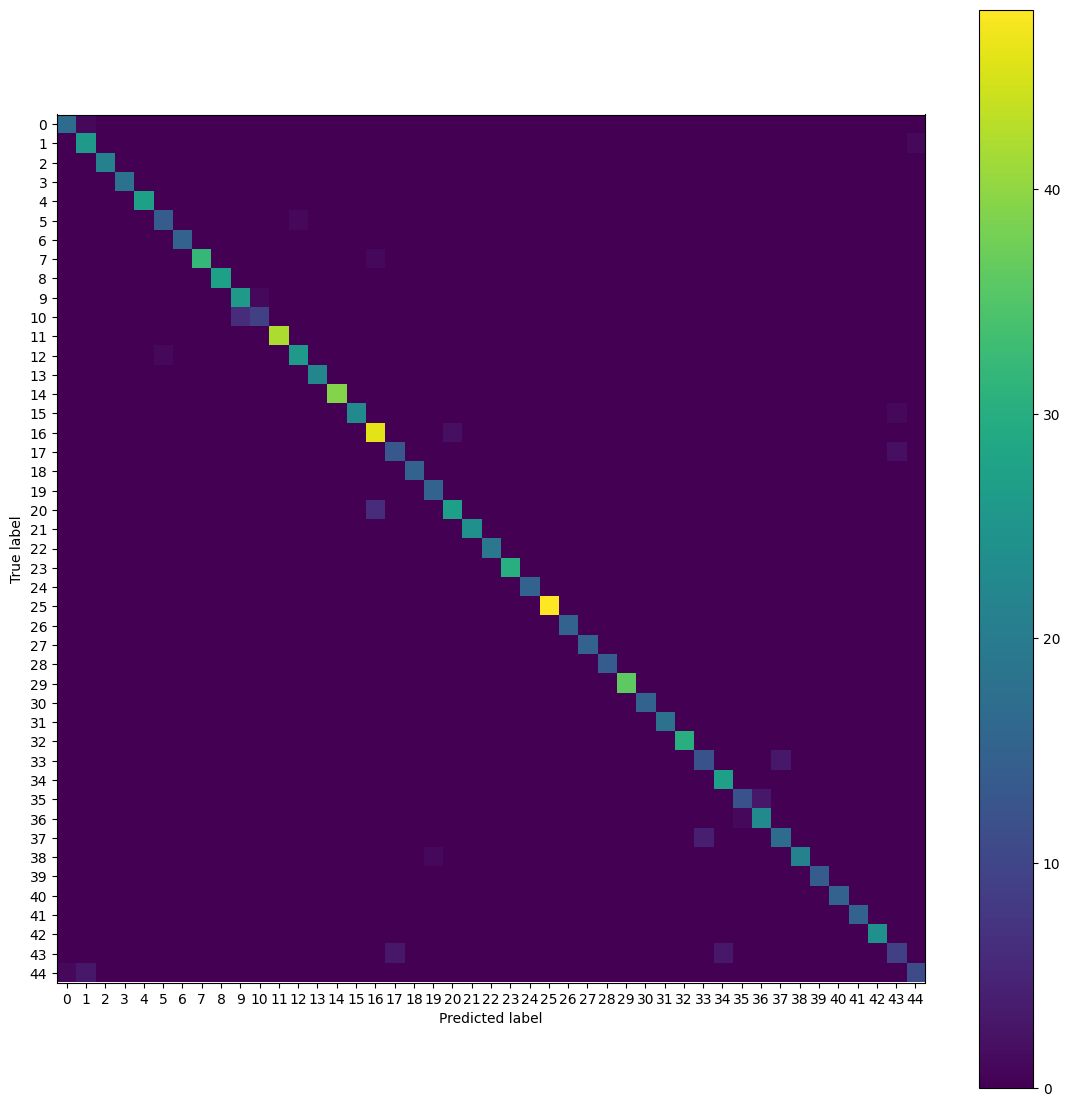

In [43]:
fig, ax = plt.subplots(figsize=(14, 14))

ConfusionMatrixDisplay.from_predictions(
    y_val_branche,
    y_pred_rf2,
    ax=ax,
    include_values=False
)

plt.show()

Classification Report

In [44]:


print(
    classification_report(
        y_val_branche,
        y_pred_rf2,
        target_names=label_encoder_branche.classes_
    )
)

                                  precision    recall  f1-score   support

                 Agroalimentaire       0.94      0.94      0.94        18
                       Agronomie       0.87      0.96      0.91        27
       Animation 3D & Jeux Vidéo       1.00      1.00      1.00        21
                      Beaux-Arts       1.00      1.00      1.00        18
                  Biotechnologie       1.00      1.00      1.00        27
          Commerce International       0.93      0.93      0.93        15
              Communication & RP       1.00      1.00      1.00        15
                   Cybersécurité       1.00      0.97      0.98        33
                Design Graphique       1.00      1.00      1.00        27
                     Droit Privé       0.81      0.96      0.88        27
                    Droit Public       0.90      0.60      0.72        15
      Développement Web & Mobile       1.00      1.00      1.00        42
    Entrepreneuriat & Management     

Validation croisée

Pour Logistic Regression

In [45]:
cv_log = cross_val_score(
    log_model2,
    X_train_branche_smote,
    y_train_branche_smote,
    cv=5,
    scoring='f1_macro'
)

print(cv_log)
print("Moyenne :", cv_log.mean())
print("Ecart-type :", cv_log.std())

[0.95369763 0.96267961 0.95067386 0.9562409  0.95286004]
Moyenne : 0.9552304072047384
Ecart-type : 0.004128968942947552


Pour KNN

In [46]:
cv_knn = cross_val_score(
    knn_model2,
    X_train_branche_smote,
    y_train_branche_smote,
    cv=5,
    scoring='f1_macro'
)

print(cv_knn)
print("Moyenne :", cv_knn.mean())
print("Ecart-type :", cv_knn.std())

[0.85314027 0.8798298  0.85436741 0.85760945 0.87215209]
Moyenne : 0.8634198060994537
Ecart-type : 0.01064815250502218


Pour Random Forest

In [47]:
cv_rf = cross_val_score(
    rf_model2,
    X_train_branche_smote,
    y_train_branche_smote,
    cv=5,
    scoring='f1_macro'
)

print(cv_rf)
print("Moyenne :", cv_rf.mean())
print("Ecart-type :", cv_rf.std())

[0.95366909 0.96170225 0.95870241 0.96241527 0.96739074]
Moyenne : 0.9607759537305472
Ecart-type : 0.004519022017140893


Pour XGBoost

In [48]:
cv_xgb = cross_val_score(
    xgb_model2,
    X_train_branche_smote,
    y_train_branche_smote,
    cv=5,
    scoring='f1_macro'
)

print(cv_xgb)
print("Moyenne :", cv_xgb.mean())
print("Ecart-type :", cv_xgb.std())

[0.9471969  0.96196458 0.95796313 0.95732734 0.95805429]
Moyenne : 0.9565012477411257
Ecart-type : 0.004932553028635269


Une validation croisée a été réalisée afin d'évaluer la robustesse des modèles. Les résultats montrent que Random Forest a obtenu les meilleures performances avec un F1-score macro moyen de 96,08 %, suivi de XGBoost (95,65 %) et de la régression logistique (95,52 %). Les faibles écarts-types observés (< 0,5 %) indiquent une bonne stabilité des modèles et suggèrent une bonne capacité de généralisation.

                                Temps d'inférence

Pour Logistic Regression

In [57]:
temps_log = []

for i in range(1000):

    debut = time.perf_counter()

    log_model2.predict(X_test_branche_processed)

    fin = time.perf_counter()

    temps_log.append(fin - debut)

print("Temps moyen :", np.mean(temps_log)*1000, "ms")

Temps moyen : 1.925058800050465 ms


Pour KNN

In [58]:
temps_knn = []

for i in range(1000):

    debut = time.perf_counter()

    knn_model2.predict(X_test_branche_processed)

    fin = time.perf_counter()

    temps_knn.append(fin - debut)

print("Temps moyen :", np.mean(temps_knn)*1000, "ms")

Temps moyen : 237.6227694001209 ms


Pour Random Forest

In [59]:
temps_rf = []

for i in range(1000):

    debut = time.perf_counter()

    rf_model2.predict(X_test_branche_processed)

    fin = time.perf_counter()

    temps_rf.append(fin - debut)

print("Temps moyen :", np.mean(temps_rf)*1000, "ms")

Temps moyen : 46.85884340007033 ms


Pour XGBoost

In [60]:
temps_xgb = []

for i in range(1000):

    debut = time.perf_counter()

    xgb_model2.predict(X_test_branche_processed)

    fin = time.perf_counter()

    temps_xgb.append(fin - debut)

print("Temps moyen :", np.mean(temps_xgb)*1000, "ms")

Temps moyen : 45.26689650003391 ms


                            SHAP